# M3 — EDA: bid book, volumes and no-buy patterns (mFRR)

Owner: Iustin (M3, learning bidders). Sprint 1 cards:
- *EDA: bid book, volumes and no-buy patterns*
- *Prototype descriptive acceptance/rejection reaction analysis*

Jean Coupon (18 Nov): start with the **weekly** auctions; check whether the bid statistics change **before a spike**.

Sections
1. Bid-book statistics per auction
2. Weekly spikes: definition (spike-and-decay shape; price/regime EDA is Carolina's card)
3. Event study: bid book before, at and after the start of a spike
4. Accepted vs rejected bids
5. Can we follow a bidder? (proxy feasibility for Week 2)
6. No-buy auctions
7. Summary and limitations

Everything "before a spike" uses only auctions whose result is published before the spike auction's gate closure (weekly: previous week's result is known 1 week before).

In [39]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

from src.data.data import build_auctions

OFFERS = ROOT / "data/raw/offers"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

# palette: categorical slots 1-2 + neutral (dataviz default palette)
C1, C2, GREY, INK = "#2a78d6", "#eb6834", "#9a9893", "#52514e"
DIR_COLOR = {"downwards": C1, "upwards": C2}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "lines.linewidth": 2,
    "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

## 1. Bid-book statistics per auction

In [40]:
offers = pd.read_parquet(OFFERS, filters=[("auction_type", "==", "mFRR")])
offers = offers[~offers["is_anticipated"]].copy()
auctions = build_auctions(str(OFFERS), product="mFRR")

mp = offers[offers["accepted"]].groupby("auction_id")["power_price"].max().rename("mp")
offers = offers.join(mp, on="auction_id")
offers["rel"] = np.log10(offers["power_price"] / offers["mp"])   # log10(bid / marginal)


def book_stats(o: pd.DataFrame) -> pd.DataFrame:
    acc, rej = o[o["accepted"]], o[~o["accepted"]]
    near = o[(o["rel"].abs() <= np.log10(1.1))]                       # within ±10 % of marginal
    s = pd.DataFrame({
        "n_acc": acc.groupby("auction_id").size(),
        "n_rej": rej.groupby("auction_id").size(),
        "acc_p10": acc.groupby("auction_id")["power_price"].quantile(0.1),
        "min_rej_above": rej[rej["power_price"] > rej["mp"]].groupby("auction_id")["power_price"].min(),
        "vol_near": near.groupby("auction_id")["offered_volume"].sum(),
    })
    return s


A = auctions.merge(book_stats(offers), left_on="auction_id", right_index=True, how="left")
A[["n_acc", "n_rej", "vol_near"]] = A[["n_acc", "n_rej", "vol_near"]].fillna(0)
A["cover"] = A["offered"] / A["awarded"].replace(0, np.nan)       # offered / awarded
A["rej_share_vol"] = 1 - A["awarded"] / A["offered"]
A["spread_acc"] = np.log10(A["marginal"] / A["acc_p10"])           # spread of accepted prices
A["gap_above"] = np.log10(A["min_rej_above"] / A["marginal"])      # headroom to next rejected bid
A["near_share"] = A["vol_near"] / A["offered"]

# weekly auctions, without the one 2019 correction auction (KORR)
W = A[(A["freq"] == "weekly") & ~A["auction_id"].str.contains("KORR")].sort_values("date")
STATS = ["n_bids", "offered", "awarded", "cover", "rej_share_vol", "n_rej",
         "near_share", "spread_acc", "gap_above"]
W.groupby("direction")[STATS].median().T.round(2)

direction,downwards,upwards
n_bids,26.50,37.00
offered,647.00,857.00
awarded,331.00,407.50
cover,2.09,2.19
rej_share_vol,0.52,0.54
n_rej,10.00,17.00
near_share,0.28,0.32
spread_acc,0.13,0.09
gap_above,0.02,0.01


**What each statistic means** (computed per auction; the table shows the median over all weekly auctions of each direction, i.e. a "typical" weekly auction):

| Statistic | Meaning |
|---|---|
| `n_bids` | number of bids submitted in the auction |
| `offered` | total MW offered by all bids |
| `awarded` | total MW Swissgrid bought |
| `cover` | offered ÷ awarded: MW on offer per MW bought (competition) |
| `rej_share_vol` | share of the offered MW that was rejected |
| `n_rej` | number of rejected bids |
| `near_share` | share of the offered MW priced within ±10 % of the marginal price |
| `spread_acc` | log10(marginal ÷ 10th-percentile accepted price): how far below the marginal price the cheap accepted bids are |
| `gap_above` | log10(cheapest rejected bid above the marginal ÷ marginal): how far above the marginal price the next rejected bid is |

Yearly medians of the weekly bid book. The **cover ratio** (offered / awarded) is the competition measure.

In [41]:
yearly = W.groupby([W["date"].dt.year, "direction"])[["n_bids", "offered", "awarded", "cover"]].median()
yearly.unstack().round(1)

n_bids           offered           awarded             cover  \
direction downwards upwards downwards upwards downwards upwards downwards   
date                                                                        
2019           22.0    32.0     600.0   857.5     156.0   293.0       4.1   
2020           24.0    30.0     544.5   785.0     220.0   326.0       2.4   
2021           27.0    42.0     762.5  1039.5     442.0   452.0       1.7   
2022           26.0    54.0     716.0  1078.5     405.5   384.0       1.8   
2023           27.0    37.5     666.5   689.5     379.5   388.5       1.9   
2024           29.0    37.0     768.0   828.0     508.0   480.0       1.6   
2025           30.5    37.0     747.0   868.5     350.0   429.0       2.1   
2026           31.0    40.0     743.0   928.0     350.0   497.0       2.3   

                   
direction upwards  
date               
2019          3.0  
2020          2.5  
2021          2.3  
2022          2.6  
2023          2.0  
2024          1.8  
2025          1.9  
2026          1.9

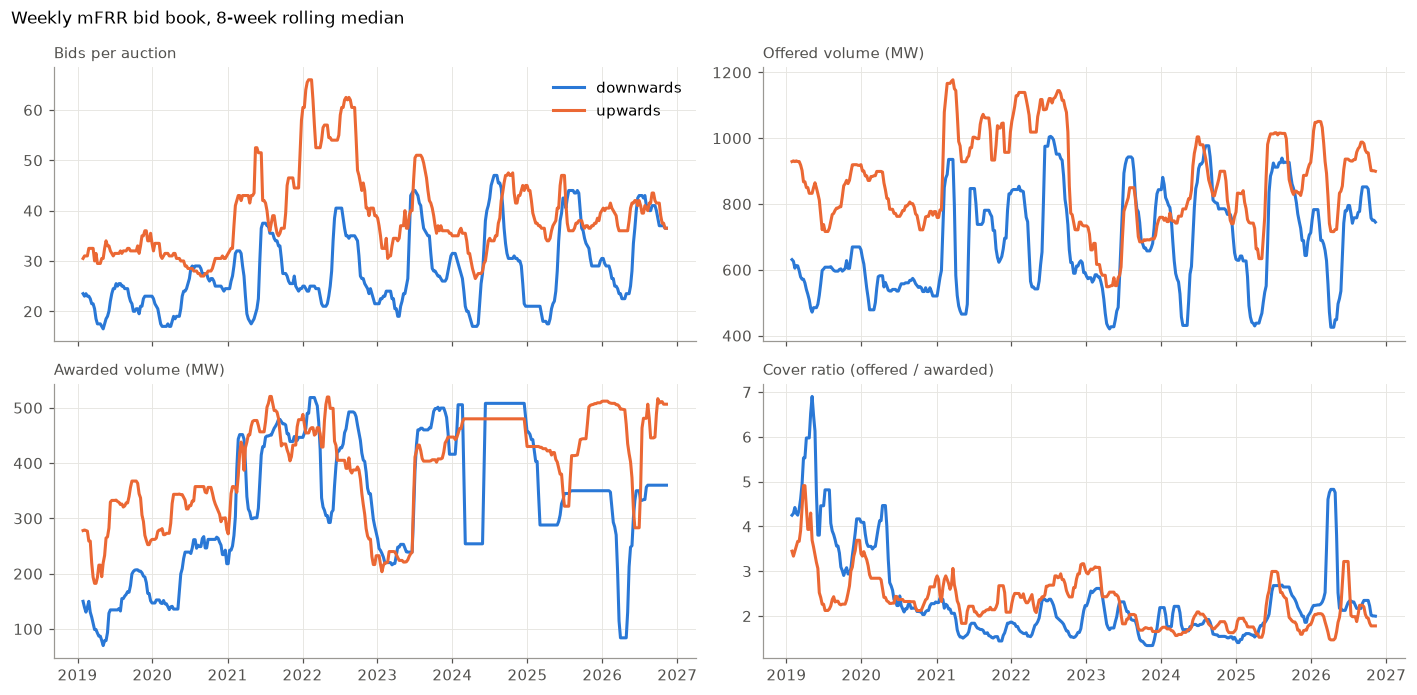

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(13, 6.4), sharex=True)
for ax, col, title in zip(axes.flat, ["n_bids", "offered", "awarded", "cover"],
                          ["Bids per auction", "Offered volume (MW)", "Awarded volume (MW)",
                           "Cover ratio (offered / awarded)"]):
    for d, g in W.groupby("direction"):
        r = g.set_index("date")[col].rolling(8, min_periods=4).median()
        ax.plot(r.index, r.values, color=DIR_COLOR[d], label=d)
    ax.set_title(title, loc="left", fontsize=10, color=INK)
axes[0, 0].legend()
fig.suptitle("Weekly mFRR bid book, 8-week rolling median", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); save(fig, "m3_weekly_book_over_time")


## 2. Weekly spikes: definition

Jean (18 Nov) describes the weekly price as **spikes and decays**. A spike is therefore defined by its **shape**, per direction:

1. **Fast rise:** the price reaches a local peak at least **0.2 log10 (×1.58)** above its lowest point of the previous **4 weeks**;
2. **Decay:** within the next **8 weeks** it falls back by at least **30 % of that rise** (it does not have to return to the start: prices often settle higher);
3. **Every sharp peak counts:** peaks only need to be at least **3 weeks** apart, so several sharp spikes in a busy period are each kept (no merging).

Each spike has a **peak** (●, the spike as the eye sees it) and an **onset** (○, the low point where the rise starts).
The analysis "before a spike" is aligned on the **first week of the rise** (onset + 1).

*Not a definition from the brief or the Swissgrid documents: our choice, to be confirmed with Jean. An earlier rule ("+41 % vs last week") marked slow climbs several times and missed rises built over a few weeks.*


In [43]:

from scipy.signal import find_peaks

# --- spike definition parameters (judgement calls, not from the brief) ---
RISE = 0.2         # minimum rise from onset to peak, in log10 (0.2 = price x1.58). Higher -> fewer, bigger spikes
UP_WEEKS = 4       # the rise must happen within this many weeks before the peak. Higher -> slower climbs also count
DECAY_WEEKS = 8    # window after the peak in which the price must fall back. Higher -> slower decays also count
DECAY_FRAC = 0.3   # the price must fall back by at least this share of the rise. Higher -> only spikes that fully reverse
MIN_GAP = 3        # minimum weeks between two peaks. Higher -> close peaks in a busy period are dropped


def spike_shape(y: pd.Series) -> tuple[list[int], list[int]]:
    # positions of spike peaks and of their onsets (start of the rise) in the weekly series y
    v = y.interpolate().to_numpy()
    candidates, _ = find_peaks(v, distance=MIN_GAP)    # local maxima, at least 3 weeks apart
    peaks, onsets = [], []
    for p in candidates:
        lo = max(0, p - UP_WEEKS)
        start = lo + int(np.argmin(v[lo:p]))             # lowest point in the weeks before the peak
        rise = v[p] - v[start]
        if rise < RISE:
            continue                                      # not a fast enough rise
        after = v[p + 1:p + 1 + DECAY_WEEKS]
        if len(after) == 0 or v[p] - after.min() < DECAY_FRAC * rise:
            continue                                      # no decay afterwards
        peaks.append(p)
        onsets.append(start)
    return peaks, onsets


def weekly_panel(direction: str) -> pd.DataFrame:
    g = W[W["direction"] == direction].set_index("date").asfreq("7D")
    g["dy"] = g["y"].diff()
    peaks, onsets = spike_shape(g["y"])
    pos = lambda idx: pd.Series(np.isin(np.arange(len(g)), idx), index=g.index)
    g["peak"] = pos(peaks)
    g["onset"] = pos(onsets)
    g["rise_start"] = pos([min(s + 1, p) for s, p in zip(onsets, peaks)])   # first week of the rise
    episode = np.zeros(len(g), dtype=bool)
    for s, p in zip(onsets, peaks):
        episode[s:p + 2] = True                                             # onset .. peak + 1 week
    g["in_episode"] = episode
    g["rise"] = np.nan
    g.loc[g["peak"], "rise"] = [g["y"].iloc[p] - g["y"].iloc[s] for s, p in zip(onsets, peaks)]
    return g


panels = {d: weekly_panel(d) for d in ["downwards", "upwards"]}
pd.DataFrame({d: {"weeks": len(g), "spikes": int(g["peak"].sum()),
                  "median rise (log10)": round(g["rise"].median(), 2),
                  "median weeks onset → peak": float(np.median(np.diff(np.c_[np.flatnonzero(g["onset"]), np.flatnonzero(g["peak"])], axis=1))),
                  "median weekly change": round(g["dy"].median(), 3)}
              for d, g in panels.items()})


,downwards,upwards
weeks,410.000,410.00
spikes,30.000,20.00
median rise (log10),0.440,0.40
median weeks onset → peak,3.000,3.00
median weekly change,-0.029,-0.02


The median weekly change over all weeks is **negative** (−0.029 log10 ≈ −6.5 %/week downwards, −0.02 ≈ −4.5 %/week upwards): most weeks the price slides down slowly, and spikes are the sudden rises (median rise ×2.8 down / ×2.5 up, reached in ~3 weeks) — a sawtooth.

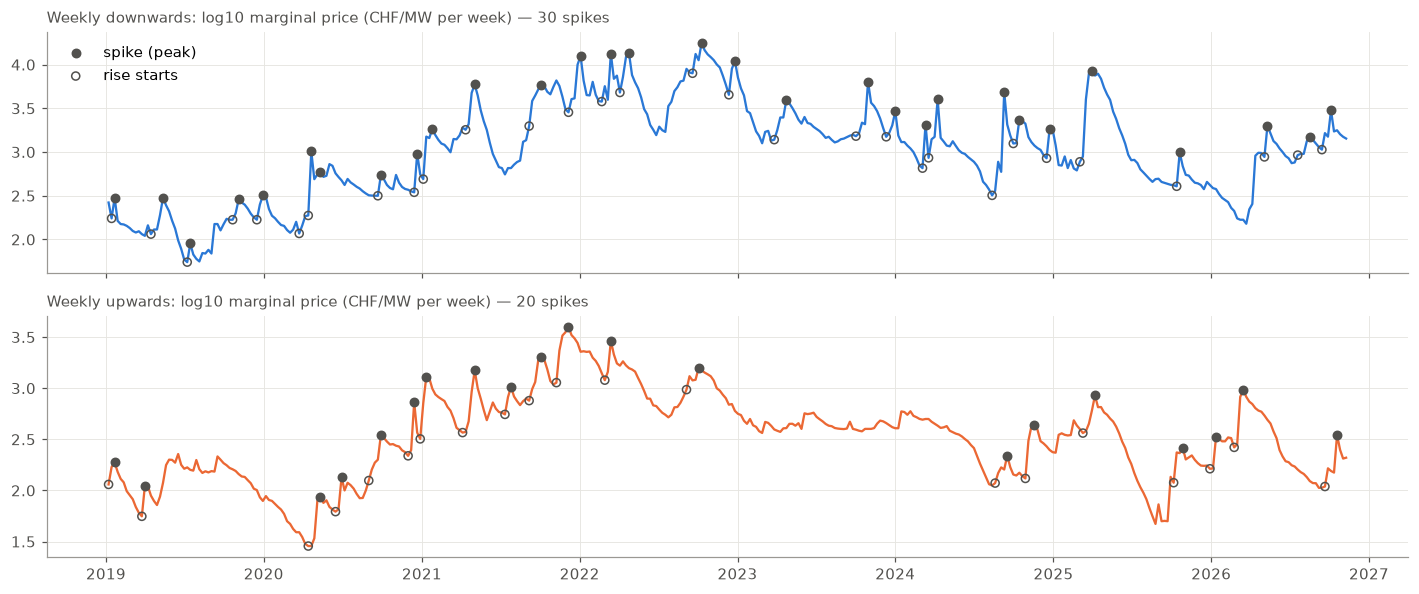

In [44]:

fig, axes = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
for ax, (d, g) in zip(axes, panels.items()):
    ax.plot(g.index, g["y"], color=DIR_COLOR[d], linewidth=1.5)
    ax.scatter(g.index[g["peak"]], g.loc[g["peak"], "y"], s=30, color=INK, zorder=3, label="spike (peak)")
    ax.scatter(g.index[g["onset"]], g.loc[g["onset"], "y"], s=28, facecolors="none", edgecolors=INK,
               zorder=3, label="rise starts")
    ax.set_title(f"Weekly {d}: log10 marginal price (CHF/MW per week) — {int(g['peak'].sum())} spikes",
                 loc="left", fontsize=10, color=INK)
axes[0].legend(loc="upper left")
fig.tight_layout(); save(fig, "m3_weekly_spikes")


In [45]:

def half_life(g: pd.DataFrame, horizon: int = 12) -> pd.Series:
    # weeks after the peak until the price has given back half of the rise
    out = []
    for t in g.index[g["peak"]]:
        peak, rise = g.at[t, "y"], g.at[t, "rise"]
        fut = g["y"].loc[t:].iloc[1:horizon + 1]
        back = fut[fut <= peak - rise / 2]
        out.append((back.index[0] - t).days // 7 if len(back) else np.nan)
    return pd.Series(out, dtype=float)

pd.DataFrame({d: {"median weeks to give back half of the rise": half_life(g).median(),
                  "share that gives back half within 12 weeks": round(half_life(g).notna().mean(), 2)}
              for d, g in panels.items()})


,downwards,upwards
median weeks to give back half of the rise,2.0,4.0
share that gives back half within 12 weeks,0.9,0.8



## 3. Event study: the bid book around a spike

**Week 0 = the first week of the rise** (onset + 1). Weeks −1, −2, … are published before week 0's auction closes → usable for forecasting.

Each statistic is a deviation from its own recent level: the median of the 8 weeks ending at week −3 (log10 for counts and volumes),
so long-run trends (e.g. more bidders in 2024 than in 2019) are not mistaken for a spike signal.
We compare spikes with **normal weeks** = weeks outside any spike episode (onset → peak + 1).


In [46]:

LOG = ["n_bids", "offered", "awarded", "cover"]
LAGS = range(-4, 5)   # k: statistic of week t+k, t = first week of the rise


def event_table(g: pd.DataFrame) -> pd.DataFrame:
    g = g.copy()
    for c in LOG:
        g[c] = np.log10(g[c])
    normal = ~g["in_episode"] & g["dy"].notna()
    rows = []
    for c in STATS + ["y"]:
        base = g[c].shift(3).rolling(8, min_periods=5).median()
        for k in LAGS:
            dev = g[c].shift(-k) - base
            rows.append({"stat": c, "k": k,
                         "spike": dev[g["rise_start"]].median(), "normal": dev[normal].median()})
    return pd.DataFrame(rows)

ev = pd.concat({d: event_table(g) for d, g in panels.items()}, names=["direction"]).reset_index(level=0)
ev[ev["k"].isin([-2, -1, 0])].pivot_table(index="stat", columns=["direction", "k"], values=["spike", "normal"]).round(3)


normal                                         spike         \
direction     downwards               upwards               downwards          
k                    -2     -1      0      -2     -1      0        -2     -1   
stat                                                                           
awarded           0.000  0.000  0.000   0.000  0.000  0.000    -0.032 -0.015   
cover            -0.001  0.004  0.007   0.008  0.012  0.010    -0.003 -0.014   
gap_above        -0.003 -0.004 -0.004  -0.000 -0.000 -0.001     0.001  0.008   
n_bids            0.000  0.000 -0.013   0.007  0.000 -0.005    -0.047 -0.050   
n_rej             0.500  0.750  1.000   1.000  1.000  0.500    -1.500  0.000   
near_share        0.017  0.031  0.056   0.022  0.033  0.044    -0.027  0.040   
offered           0.004  0.009  0.009   0.011  0.012  0.008    -0.048 -0.052   
rej_share_vol    -0.000  0.005  0.007   0.009  0.009  0.010    -0.004 -0.014   
spread_acc       -0.020 -0.026 -0.031  -0.006 -0.010 -0.013     0.001 -0.010   
y                -0.059 -0.085 -0.092  -0.037 -0.051 -0.059    -0.038 -0.055   

                                            
direction            upwards                
k                  0      -2     -1      0  
stat                                        
awarded       -0.005   0.000  0.000  0.003  
cover         -0.046  -0.026 -0.038 -0.067  
gap_above      0.071  -0.002 -0.002  0.016  
n_bids        -0.089  -0.041 -0.032 -0.025  
n_rej         -3.000  -1.500 -2.500 -7.000  
near_share    -0.162  -0.062 -0.038 -0.152  
offered       -0.077  -0.015 -0.038 -0.046  
rej_share_vol -0.045  -0.027 -0.047 -0.070  
spread_acc     0.101  -0.022 -0.010  0.103  
y              0.125  -0.049 -0.072  0.036

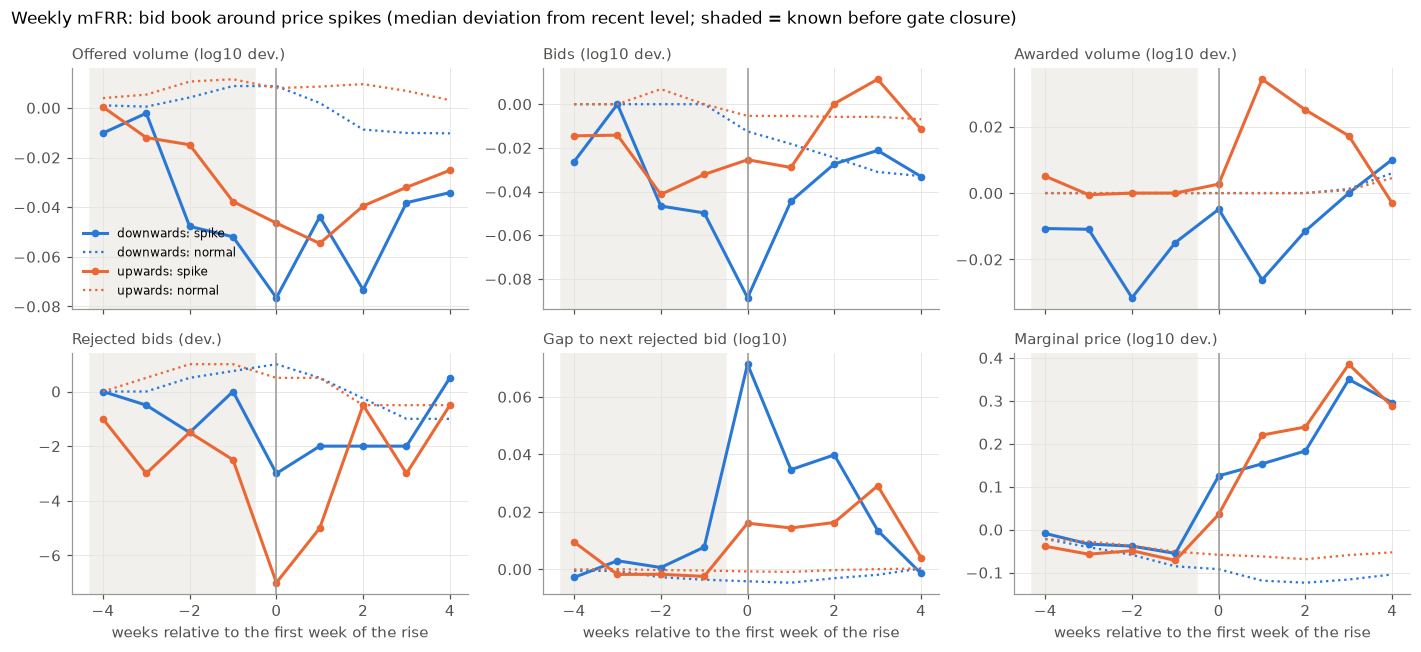

In [47]:

show = [("offered", "Offered volume (log10 dev.)"), ("n_bids", "Bids (log10 dev.)"),
        ("awarded", "Awarded volume (log10 dev.)"), ("n_rej", "Rejected bids (dev.)"),
        ("gap_above", "Gap to next rejected bid (log10)"), ("y", "Marginal price (log10 dev.)")]
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for ax, (c, title) in zip(axes.flat, show):
    for d in ["downwards", "upwards"]:
        e = ev[(ev["direction"] == d) & (ev["stat"] == c)]
        ax.plot(e["k"], e["spike"], color=DIR_COLOR[d], marker="o", markersize=4, label=f"{d}: spike")
        ax.plot(e["k"], e["normal"], color=DIR_COLOR[d], linestyle=":", linewidth=1.5, label=f"{d}: normal")
    ax.axvline(0, color=GREY, linewidth=1); ax.axvspan(-4.3, -0.5, color="#f1f0ec", zorder=0)
    ax.set_title(title, loc="left", fontsize=10, color=INK)
for ax in axes[1]:
    ax.set_xlabel("weeks relative to the first week of the rise")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Weekly mFRR: bid book around price spikes (median deviation from recent level; shaded = known before gate closure)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout(); save(fig, "m3_prespike_event_study")


Is the pre-spike signal real? Mann-Whitney test and AUC of each statistic in the week **before the rise starts** (known before gate closure), both directions pooled, spikes vs normal weeks.

In [48]:

def t1_deviation(g: pd.DataFrame) -> pd.DataFrame:
    g = g.copy()
    for c in LOG:
        g[c] = np.log10(g[c])
    D = pd.DataFrame({c: g[c].shift(1) - g[c].shift(3).rolling(8, min_periods=5).median() for c in STATS})
    D["spike"] = g["rise_start"]
    keep = g["rise_start"] | (~g["in_episode"] & g["dy"].notna())
    return D[keep].dropna()

D = pd.concat([t1_deviation(g) for g in panels.values()])
rows = []
for c in STATS:
    s, n = D.loc[D["spike"], c], D.loc[~D["spike"], c]
    auc = roc_auc_score(D["spike"], D[c])
    rows.append({"stat (week before the rise)": c, "median spike": s.median(), "median normal": n.median(),
                 "p (Mann-Whitney)": mannwhitneyu(s, n).pvalue,
                 "AUC": max(auc, 1 - auc), "direction": "higher → spike" if auc > 0.5 else "lower → spike"})
print(f"{int(D['spike'].sum())} spikes / {int((~D['spike']).sum())} normal weeks")
pd.DataFrame(rows).set_index("stat (week before the rise)").sort_values("p (Mann-Whitney)").round(4)


48 spikes / 576 normal weeks


,median spike,median normal,p (Mann-Whitney),AUC,direction
stat (week before the rise),,,,,
offered,-0.0385,0.0105,0.0000,0.6813,lower → spike
n_bids,-0.0414,0.0000,0.0004,0.6545,lower → spike
n_rej,-1.0000,1.0000,0.0355,0.5912,lower → spike
rej_share_vol,-0.0197,0.0081,0.0478,0.5859,lower → spike
awarded,-0.0002,0.0000,0.0789,0.5762,lower → spike
gap_above,0.0013,-0.0013,0.0913,0.5733,higher → spike
cover,-0.0187,0.0069,0.1377,0.5645,lower → spike
spread_acc,-0.0101,-0.0145,0.6602,0.5191,higher → spike
near_share,0.0160,0.0322,0.7575,0.5134,lower → spike


## 4. Accepted vs rejected bids

`rel = log10(bid price / marginal price)` of the same auction: 0 = at the marginal price.

In [49]:
B = offers[offers["mp"].notna()]
pd.concat({f: B[B["auction_frequency"] == f].groupby("accepted")["rel"].quantile([.1, .25, .5, .75, .9]).unstack()
           for f in ["weekly", "daily"]}).round(2)

0.10  0.25  0.50  0.75  0.90
       accepted                              
weekly False     0.00  0.03  0.17  0.64  1.08
       True     -0.26 -0.14 -0.06 -0.02 -0.01
daily  False     0.00  0.09  0.51  1.32  2.15
       True     -0.62 -0.30 -0.11 -0.01  0.00

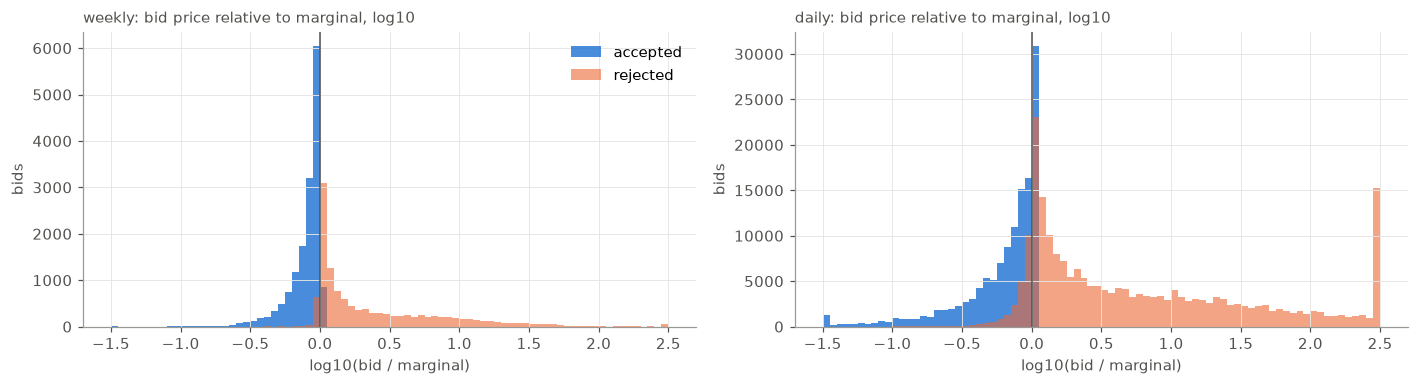

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=False)
bins = np.linspace(-1.5, 2.5, 81)
for ax, f in zip(axes, ["weekly", "daily"]):
    x = B[B["auction_frequency"] == f]
    ax.hist(x.loc[x["accepted"], "rel"].clip(-1.5, 2.5), bins=bins, color=C1, alpha=0.85, label="accepted")
    ax.hist(x.loc[~x["accepted"], "rel"].clip(-1.5, 2.5), bins=bins, color=C2, alpha=0.6, label="rejected")
    ax.axvline(0, color=INK, linewidth=1)
    ax.set_title(f"{f}: bid price relative to marginal, log10", loc="left", fontsize=10, color=INK)
    ax.set_xlabel("log10(bid / marginal)"); ax.set_ylabel("bids")
axes[0].legend()
fig.tight_layout(); save(fig, "m3_accepted_vs_rejected_price")

In [51]:
pd.concat({f: B[B["auction_frequency"] == f].groupby("accepted")["offered_volume"].quantile([.1, .5, .9]).unstack()
           for f in ["weekly", "daily"]})

0.1   0.5   0.9
       accepted                 
weekly False     5.0  10.0  75.0
       True      5.0  10.0  58.0
daily  False     5.0  15.0  86.0
       True      5.0  10.0  60.0

**Out-of-merit rejections.** The brief says a bid below the marginal price is *almost always* accepted. Here, in ~46 % of
auctions at least one cheaper bid is rejected. Is it because the bid was larger than the volume still needed (indivisible bid)?

In [52]:
X = B.sort_values(["auction_id", "power_price"]).copy()
X["awarded_cheaper"] = X.groupby("auction_id")["awarded_volume"].cumsum() - X["awarded_volume"]
X["remaining_need"] = X.groupby("auction_id")["awarded_volume"].transform("sum") - X["awarded_cheaper"]
oom = X[~X["accepted"] & (X["power_price"] < X["mp"])]
both = B.groupby("auction_id")["accepted"].agg(["any", "all"])
n_two_sided = int((both["any"] & ~both["all"]).sum())
pd.Series({
    "auctions with accepted and rejected bids": n_two_sided,
    "auctions with a rejected bid below marginal": oom["auction_id"].nunique(),
    "share of those auctions": round(oom["auction_id"].nunique() / n_two_sided, 3),
    "rejected bids below marginal": len(oom),
    "share larger than remaining need (indivisible?)": round((oom["offered_volume"] > oom["remaining_need"]).mean(), 3),
    "partially accepted bids": int(((B["awarded_volume"] > 0) & (B["awarded_volume"] < B["offered_volume"])).sum()),
})

auctions with accepted and rejected bids           29358.000
auctions with a rejected bid below marginal        13416.000
share of those auctions                                0.457
rejected bids below marginal                       22226.000
share larger than remaining need (indivisible?)        0.252
partially accepted bids                            30413.000
dtype: float64

## 5. Can we follow a bidder? (comparable groups for Week 2)

No bidder IDs. Idea: use the bid **volume** as a fingerprint between consecutive weekly auctions of the same direction.

In [53]:
print("most common bid sizes (MW):", offers["offered_volume"].value_counts().head(10).to_dict())

tracked, total = 0, 0
for d, g in offers[(offers["auction_frequency"] == "weekly") & ~offers["auction_id"].str.contains("KORR")].groupby("direction"):
    vols = g.groupby("auction_id")["offered_volume"].apply(lambda v: v.value_counts())
    ids = g.groupby("auction_id")["date"].first().sort_values().index
    for prev, cur in zip(ids[:-1], ids[1:]):
        vp, vc = vols.loc[prev], vols.loc[cur]
        tracked += len(set(vp[vp == 1].index) & set(vc[vc == 1].index))
        total += int(vc.sum())
print(f"bids with a volume unique in both consecutive weekly auctions: {tracked} / {total} = {tracked / total:.1%}")

most common bid sizes (MW): {10: 88911, 5: 82111, 20: 31528, 100: 25943, 30: 22725, 50: 16039, 7: 13699, 15: 10946, 60: 9780, 25: 8491}
bids with a volume unique in both consecutive weekly auctions: 2301 / 27547 = 8.4%


→ Volume alone is a weak fingerprint (sizes are standardised: 5, 10, 20, 100 MW). Week 2 options:
match on (volume, nearest price) between consecutive auctions; or work at the level of the **supply curve**
(price quantiles of the order book) instead of individual bidders.

## 6. No-buy auctions (daily only — every weekly auction buys something)

In [54]:
Dd = A[A["freq"] == "daily"].copy()
Dd["no_buy"] = Dd["y"].isna()
Dd.groupby([Dd["date"].dt.year, "direction"])["no_buy"].mean().unstack().round(3)

direction,downwards,upwards
date,,
2019,0.053,0.001
2020,0.002,0.065
2021,0.115,0.063
2022,0.153,0.100
2023,0.192,0.115
2024,0.910,0.826
2025,0.000,0.000
2026,0.026,0.004


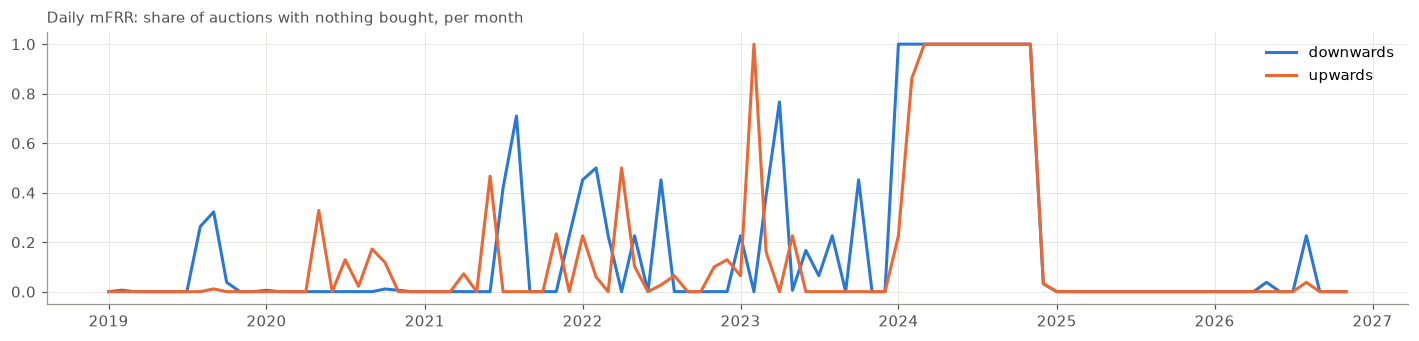

In [55]:
m = Dd.groupby([pd.Grouper(key="date", freq="MS"), "direction"])["no_buy"].mean().unstack()
fig, ax = plt.subplots(figsize=(13, 3.2))
for d in m.columns:
    ax.plot(m.index, m[d], color=DIR_COLOR[d], label=d)
ax.set_title("Daily mFRR: share of auctions with nothing bought, per month", loc="left", fontsize=10, color=INK)
ax.legend(); fig.tight_layout(); save(fig, "m3_nobuy_share")

No-buy periods come in **whole delivery weeks** (runs of 42 blocks = 7 days × 6 blocks). Check the week-level structure and the link to the weekly auction of the same week (which closes before the daily ones):

In [56]:
Dd["week"] = Dd["date"] - pd.to_timedelta(Dd["date"].dt.day_of_week, unit="D")
wk = Dd.groupby(["week", "direction"])["no_buy"].mean().rename("nb_share").reset_index()
print("week × direction cells that are all-or-nothing:", round(((wk["nb_share"] == 0) | (wk["nb_share"] == 1)).mean(), 3))

wa = W.groupby(["date", "direction"])["awarded"].sum().rename("weekly_awarded").reset_index().rename(columns={"date": "week"})
wk = wk.merge(wa, on=["week", "direction"])
wk = wk[wk["week"].dt.year != 2024]          # 2024 = near-total suspension, see below
rows = []
for d, g in wk.sort_values("week").groupby("direction"):
    g = g.copy()
    g["weekly_awarded_rel"] = np.log10(g["weekly_awarded"] / g["weekly_awarded"].shift(1).rolling(8, min_periods=4).median())
    g = g.dropna(subset=["weekly_awarded_rel"]); full = g["nb_share"] == 1
    rows.append({"direction": d, "weeks": len(g), "full no-buy weeks": int(full.sum()),
                 "weekly awarded vs usual (no-buy weeks)": g.loc[full, "weekly_awarded_rel"].median(),
                 "weekly awarded vs usual (other weeks)": g.loc[~full, "weekly_awarded_rel"].median(),
                 "AUC": roc_auc_score(full, g["weekly_awarded_rel"])})
pd.DataFrame(rows).set_index("direction").round(3)

week × direction cells that are all-or-nothing: 0.966


,weeks,full no-buy weeks,weekly awarded vs usual (no-buy weeks),weekly awarded vs usual (other weeks),AUC
direction,,,,,
downwards,353,27,0.050,-0.000,0.732
upwards,353,13,0.072,-0.003,0.841


In [57]:
runs = []
for d, g in Dd.sort_values(["date", "block"]).groupby("direction"):
    r = (g["no_buy"] != g["no_buy"].shift()).cumsum()
    t = g.groupby(r).agg(no_buy=("no_buy", "first"), start=("date", "min"), end=("date", "max"), blocks=("no_buy", "size"))
    t["direction"] = d
    runs.append(t[t["no_buy"] & (t["blocks"] >= 200)])
pd.concat(runs)[["direction", "start", "end", "blocks"]]

,direction,start,end,blocks
no_buy,,,,
90,downwards,2024-01-01,2024-12-01,1830
96,upwards,2023-01-30,2023-03-05,210
102,upwards,2024-02-05,2024-12-01,1614


## 7. Summary (Sprint 1, M3)

**Weekly spikes (Jean's question).**
- Spike = fast rise (≥ ×1.58 within 4 weeks) to a peak, then a decay (≥ 30 % of the rise within 8 weeks), every sharp peak counted: **30 downwards + 20 upwards**. Median rise ×2.8 (down) / ×2.5 (up), reached in ~3 weeks; half of it is given back after a median of ~2 (down) / ~4 (up) weeks.
- Between spikes the price drifts slowly down (median weekly change < 0): a sawtooth.
- **Yes, the bid book changes before a spike.** In the week before the rise starts (known at gate closure), **offered volume (p < 1e-4, AUC 0.68) and the number of bids (p = 4e-4, AUC 0.65) are lower than usual**; fewer bids are rejected (p ≈ 0.04–0.05, weak).
- **Awarded volume (Swissgrid's demand) does not move before spikes** (p = 0.08, not significant) → spikes look **supply-driven** (thinner book). For upward spikes, awarded volume rises slightly (~+5 %) *during* the rise, not before.
- Each signal alone is moderate (AUC ≤ 0.68): useful as features, not as a spike alarm.
- Long-run: the cover ratio fell from ~3–4 (2019) to ~1.7 (2021–24) while prices rose.

**Accepted vs rejected.**
- Weekly accepted bids sit tightly below the marginal (median −13 %); rejected bids median ~1.5× above. Daily books are much wider.
- ~46 % of two-sided auctions reject at least one bid *cheaper* than the marginal; only ~25 % of those are explained by "bid larger than remaining need" → clearing is not a pure merit order: indivisible step offers and joint TRL + aFRR cost minimisation (see `reports/m3_market_notes.md`).
- ~30 k bids are partially accepted.

**Following bidders.** Bid sizes are standardised; only ~8 % of weekly bids can be tracked by a unique volume → use (volume, price) matching or supply-curve-level analysis in Week 2.

**No-buy auctions.**
- Daily only. They come in whole delivery weeks (97 % of week × direction cells are all-or-nothing) and coincide with **higher-than-usual weekly awarded volume** of the same week (AUC 0.73 down / 0.84 up) → predictable from the weekly auction, which closes first.
- **2024: daily procurement almost suspended** (down: 2024-01-01 → 2024-12-01; up: 2024-02-05 → 2024-12-01). Resumes in December 2024; no no-buy auction in 2025.

**Limitations.** No bidder IDs; the spike definition is our choice (to confirm with Jean); 50 spikes is a small sample; 31 missing daily dates in 2024.